# Engenharia de Features: Olist

## Objetivo

Transformar a base analítica (1 linha por pedido) em **atributos úteis para prever o atraso**,
sem *data leakage*. Este notebook documenta e **justifica com dados** as features criadas em
`module_olist/features.py`, que é o código usado de fato pelo pipeline.

Roteiro:

1. Revisar o que pode e o que não pode ser usado (data leakage).
2. Construir a base com o código do projeto.
3. Justificar cada nova feature com a taxa de atraso.
4. *Feature encoding*: One-Hot nas categóricas.
5. *Feature transformation*: por que não aplicamos scaling.
6. *Feature selection*: quanto cada feature informa sobre o atraso.

## 1. Data leakage: o que já sabemos no instante da previsão

A previsão acontece em `order_approved_at`.

| O que já sabemos (pode virar feature) | O que **não** conhecemos (não pode) |
|---|---|
| data da compra | data real da entrega |
| data de aprovação | data de envio à transportadora |
| prazo prometido | avaliação do cliente |
| produtos e vendedores | status final do pedido |
| preço e frete | |
| estado do cliente | |

> A data real de entrega é usada **apenas** para construir o alvo `is_late`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif

from module_olist.config import RAW_DATA_DIR
from module_olist.dataset import create_dataset, load_dataset
from module_olist.features import (
    CATEGORICAL_FEATURES,
    FEATURES,
    NUMERIC_FEATURES,
    create_features,
)
from module_olist.pipeline import create_preprocessor
from module_olist.split import split_data

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid", palette="Blues_r")

2026-10-26 23:41:38.468 | INFO     | module_olist.config:<module>:11 - PROJ_ROOT path is: D:\OneDrive\Área de Trabalho\curso_ml_cimatec\olist


## 2. Base refinada com o código do projeto

Usamos as mesmas funções do pipeline (`load_dataset` → `create_dataset` → `create_features`),
assim o que analisamos aqui é exatamente o que o modelo recebe.

In [2]:
orders, items, customers = load_dataset(
    orders_path=RAW_DATA_DIR / "olist_orders_dataset.csv",
    items_path=RAW_DATA_DIR / "olist_order_items_dataset.csv",
    customers_path=RAW_DATA_DIR / "olist_customers_dataset.csv",
)

data = create_dataset(orders, items, customers)
data = create_features(data)

print("Base refinada:", data.shape)
print("Taxa geral de atraso: {:.2%}".format(data["is_late"].mean()))

data[FEATURES].head()

2026-10-26 23:41:41.424 | INFO     | module_olist.dataset:create_target:91 - Pedidos originais: 99,441
2026-10-26 23:41:41.425 | INFO     | module_olist.dataset:create_target:94 - Pedidos no recorte histórico: 96,456
2026-10-26 23:41:41.427 | INFO     | module_olist.dataset:create_target:99 - Pedidos entregues no prazo: 88,630
2026-10-26 23:41:41.429 | INFO     | module_olist.dataset:create_target:103 - Pedidos entregues com atraso: 7,826
2026-10-26 23:41:42.454 | INFO     | module_olist.features:create_features:90 - Pedidos removidos por prazo não positivo: 6
2026-10-26 23:41:42.502 | INFO     | module_olist.features:create_features:134 - Features criadas. Base refinada com 96,450 pedidos.
Base refinada: (96450, 24)
Taxa geral de atraso: 8.11%


,promised_days,item_count,seller_count,total_price,total_freight,approval_hours,avg_item_price,freight_ratio,is_short_deadline,is_weekend_purchase,purchase_hour,purchase_weekday,purchase_month,customer_state
0,15.536632,1,1,29.99,8.72,0.178333,29.99,0.290764,0,0,10,0,10,SP
1,17.858021,1,1,118.70,22.76,30.713889,118.70,0.191744,0,0,20,1,7,BA
2,26.628206,1,1,159.90,19.22,0.276111,159.90,0.120200,0,0,8,2,8,GO
3,26.176400,1,1,45.00,27.20,0.298056,45.00,0.604444,0,1,19,5,11,RN
4,12.069109,1,1,19.90,8.72,1.030556,19.90,0.438191,0,0,21,1,2,SP


## 3. Justificativa das novas features

Para cada feature comparamos a **taxa de atraso** entre grupos. Uma feature útil separa
pedidos de risco maior e menor.

In [3]:
def late_rate_by(column, bins=None, labels=None, q=None):
    # Agrupa por faixas (bins), quantis (q) ou pelos próprios valores,
    # e calcula quantidade de pedidos e taxa de atraso em cada grupo.
    if q is not None:
        groups = pd.qcut(data[column], q=q, duplicates="drop")
    elif bins is not None:
        groups = pd.cut(data[column], bins=bins, labels=labels)
    else:
        groups = data[column]

    summary = (
        data.groupby(groups, observed=True)
        .agg(pedidos=("is_late", "size"), taxa_atraso=("is_late", "mean"))
        .reset_index()
    )
    summary["taxa_atraso"] = (summary["taxa_atraso"] * 100).round(2)
    return summary

### 3.1 `is_short_deadline`: prazo de até 7 dias

**Hipótese (EDA, pergunta 2):** prazos curtos deixam pouca margem para imprevistos.

In [4]:
late_rate_by("is_short_deadline")

,is_short_deadline,pedidos,taxa_atraso
0,0,94813,7.76
1,1,1637,28.34


### 3.2 `approval_hours`: horas entre a compra e a aprovação

**Hipótese:** quando a aprovação demora (ex.: boleto), parte da folga do prazo já foi consumida.

In [5]:
display(data["approval_hours"].describe().to_frame().T.round(2))
late_rate_by("approval_hours", q=5)

,count,mean,std,min,25%,50%,75%,max
approval_hours,96450.0,10.27,20.48,0.0,0.22,0.34,14.51,741.44


,approval_hours,pedidos,taxa_atraso
0,"(-0.001, 0.201]",19385,6.90
1,"(0.201, 0.272]",19222,7.23
2,"(0.272, 0.61]",19266,7.96
3,"(0.61, 21.187]",19287,8.75
4,"(21.187, 741.444]",19290,9.72


### 3.3 `avg_item_price`: preço médio por item

**Hipótese:** itens mais caros tendem a ser maiores ou mais complexos de transportar.

In [6]:
late_rate_by("avg_item_price", q=5)

,avg_item_price,pedidos,taxa_atraso
0,"(0.849, 35.0]",19388,7.27
1,"(35.0, 59.9]",19804,7.60
2,"(59.9, 99.0]",18981,8.06
3,"(99.0, 159.0]",19083,8.23
4,"(159.0, 6735.0]",19194,9.41


### 3.4 `freight_ratio`: frete ÷ valor dos produtos

**Hipótese:** frete proporcionalmente alto indica destino distante ou produto volumoso.

In [7]:
late_rate_by("freight_ratio", q=5)

,freight_ratio,pedidos,taxa_atraso
0,"(-0.001, 0.115]",19290,8.26
1,"(0.115, 0.183]",19290,7.92
2,"(0.183, 0.274]",19297,7.60
3,"(0.274, 0.435]",19288,8.40
4,"(0.435, 21.447]",19285,8.37


### 3.5 `is_weekend_purchase`: compra no sábado ou domingo

**Hipótese:** compras de fim de semana só começam a ser processadas no próximo dia útil.

In [8]:
late_rate_by("is_weekend_purchase")

,is_weekend_purchase,pedidos,taxa_atraso
0,0,74273,8.28
1,1,22177,7.54


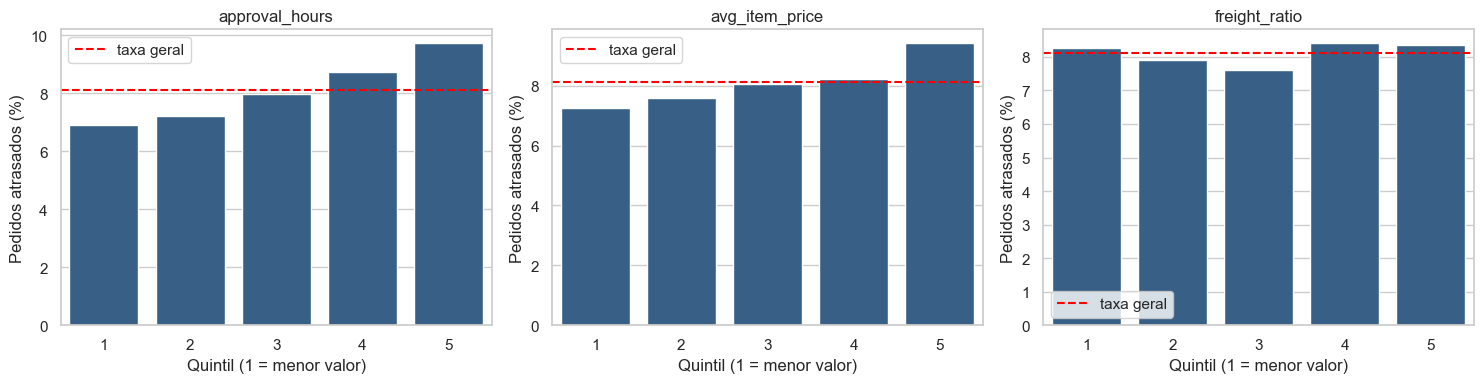

In [9]:
# Visão geral: taxa de atraso por quintil das features numéricas novas
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, column in zip(axes, ["approval_hours", "avg_item_price", "freight_ratio"]):
    summary = late_rate_by(column, q=5)
    sns.barplot(x=range(1, len(summary) + 1), y=summary["taxa_atraso"], color="#2B6094", ax=ax)
    ax.axhline(data["is_late"].mean() * 100, color="red", linestyle="--", label="taxa geral")
    ax.set(xlabel="Quintil (1 = menor valor)", ylabel="Pedidos atrasados (%)", title=column)
    ax.legend()

plt.tight_layout()
plt.show()

**Leitura dos resultados**

| Feature | Evidência | Decisão |
|---|---|---|
| `is_short_deadline` | ~28% de atraso com prazo de até 7 dias x ~8% no restante | **Forte**: manter |
| `approval_hours` | atraso sobe de forma consistente do 1º ao 5º quintil | **Útil**: manter |
| `avg_item_price` | atraso sobe de forma consistente do 1º ao 5º quintil | **Útil**: manter |
| `freight_ratio` | taxa sobe e desce entre os quintis (relação não monotônica) | **Manter**: a seleção abaixo mostra que ela é informativa |
| `is_weekend_purchase` | fim de semana atrasa um pouco **menos** | **Fraca**: mantida; a seleção abaixo confirma o peso |

## 4. Feature encoding: One-Hot Encoding

Modelos precisam de números. Para as categóricas usamos **One-Hot Encoding** (uma coluna 0/1 por
categoria) em vez de **Label Encoding** (1, 2, 3...), porque não existe ordem entre estados e
o Label Encoding criaria uma ordem artificial (ex.: "SP > BA").

O encoder fica **dentro do pipeline** (`create_preprocessor`) e é ajustado **só no treino**,
evitando vazamento de informação do teste. `handle_unknown="ignore"` garante que uma categoria
nova na inferência não quebre o modelo.

In [10]:
X_train, X_test, y_train, y_test = split_data(data)

preprocessor = create_preprocessor()
X_train_encoded = preprocessor.fit_transform(X_train)   # fit SOMENTE no treino
X_test_encoded = preprocessor.transform(X_test)         # teste só é transformado

print("Colunas antes do encoding:", X_train.shape[1])
print("Colunas depois do encoding:", X_train_encoded.shape[1])

encoded_names = preprocessor.get_feature_names_out()
pd.Series(encoded_names).str.split("__").str[0].value_counts()

Colunas antes do encoding: 14
Colunas depois do encoding: 80


categorical    70
numeric        10
Name: count, dtype: int64

## 5. Feature transformation: por que não aplicamos scaling

Preço e frete são muito assimétricos, mas **não** aplicamos `StandardScaler` nem log:
os modelos usados (Gradient Boosting, XGBoost e LightGBM) são **baseados em árvores**, que
dividem os dados por limiares ("preço > 150?"). Mudar a escala não altera essas divisões.

Scaling seria necessário em modelos baseados em distância ou gradiente sobre os pesos de entrada
(regressão logística, KNN, SVM, redes neurais).

## 6. Feature selection: quanto cada feature informa sobre o atraso

Usamos **Mutual Information**, que mede dependência (inclusive **não linear**) entre a feature e
o alvo. É calculada **apenas no conjunto de treino**.

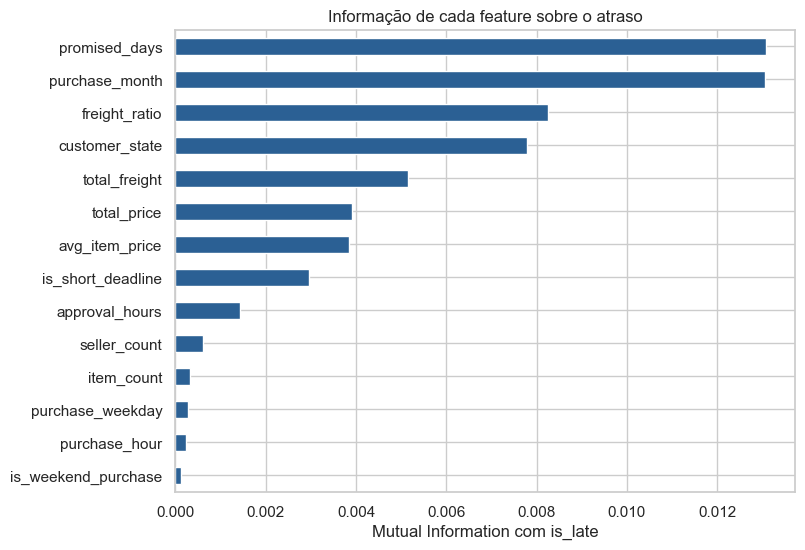

,mutual_info
promised_days,0.0131
purchase_month,0.0130
freight_ratio,0.0083
customer_state,0.0078
total_freight,0.0051
total_price,0.0039
avg_item_price,0.0038
is_short_deadline,0.0030
approval_hours,0.0014
seller_count,0.0006


In [11]:
X_mi = X_train.copy()

# Mutual information precisa de números: o estado vira um código só para esta medição
X_mi["customer_state"] = X_mi["customer_state"].astype("category").cat.codes

# Colunas discretas: categóricas, flags 0/1 e contagens inteiras
DISCRETE = CATEGORICAL_FEATURES + ["item_count", "seller_count", "is_short_deadline", "is_weekend_purchase"]
discrete = [column in DISCRETE for column in X_mi.columns]

mutual_info = pd.Series(
    mutual_info_classif(X_mi, y_train, discrete_features=discrete, random_state=42),
    index=X_mi.columns,
).sort_values()

ax = mutual_info.plot.barh(color="#2B6094", figsize=(8, 6))
ax.set(xlabel="Mutual Information com is_late", title="Informação de cada feature sobre o atraso")
plt.show()

mutual_info.sort_values(ascending=False).round(4).to_frame("mutual_info")

## Conclusão

- Foram criadas **5 novas features**, todas calculadas com informações disponíveis na aprovação
  do pagamento: `is_short_deadline`, `approval_hours`, `avg_item_price`, `freight_ratio` e
  `is_weekend_purchase`.
- Pedidos com **prazo prometido não positivo** (inconsistência apontada no notebook de qualidade)
  são removidos antes da modelagem.
- As categóricas recebem **One-Hot Encoding** dentro do pipeline, ajustado só no treino.
- Não aplicamos scaling porque os modelos são baseados em árvores.
- A lista oficial de features está em `features.py` e é usada por `split.py`, `pipeline.py` e
  `inference.py`, garantindo que treino e inferência usem exatamente as mesmas colunas.
- A *Mutual Information* aponta **prazo prometido, mês da compra, frete relativo
  (`freight_ratio`) e estado** como as variáveis mais informativas. Hora, dia da semana e
  `is_weekend_purchase` quase não informam sozinhas; ficam no modelo por enquanto e terão o
  peso real avaliado pelo modelo e, depois, pelo SHAP.